## HDBSCAN
### Clustering

In [1]:
#%reset -f 
%pip install nltk
import nltk
nltk.download('punkt')
nltk.download('wordnet')
%pip install WordCloud
%pip install hdbscan
#reset kernel
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from hdbscan import HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score
from sklearn.model_selection import train_test_split

from wordcloud import WordCloud


[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package punkt to /home/jack/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


We could not execute HDBSCAN on the whole dataset due to memory constraint, therefore we used a subsample.
We considered using KMeans results

In [ ]:
subsample_mask = np.load("subsample_mask.npy")

data = pd.read_csv(f"without_stopwords_150.csv")
data=data[subsample_mask]

#read npy file (pre-processing was done in 'unsupervised-pre-processing.ipynb')
X = np.load('X_reduced_150_stemmer_BoW.npy')
X=X[subsample_mask]

Testing with hyperparameters:  {'min_cluster_size': 6, 'min_samples': 6}
Cluster persistence: [0.03228478 0.0523867  0.10559938 0.12532875 0.48107503]


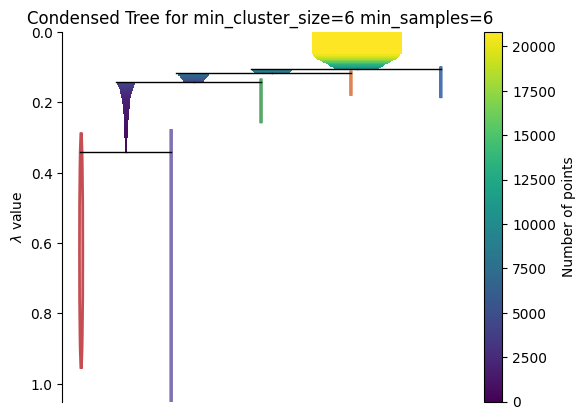

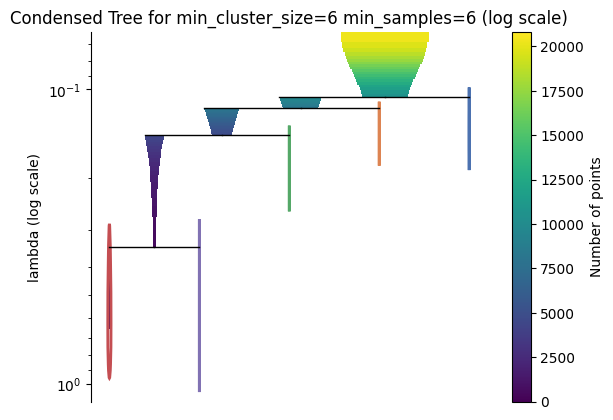

Silhouette Score (excluding outliers): 0.3456283937517558


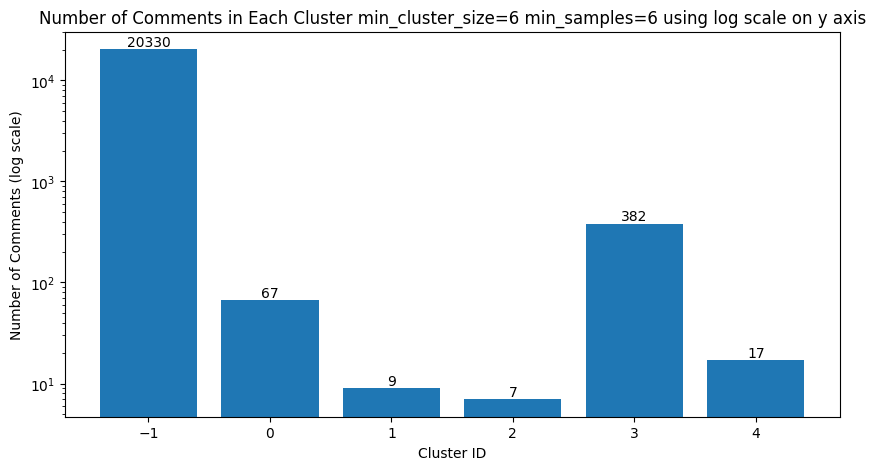

Cluster sizes:
 -1    20330
 3      382
 0       67
 4       17
 1        9
 2        7
Name: count, dtype: int64




Testing with hyperparameters:  {'min_cluster_size': 6, 'min_samples': 3}
Cluster persistence: [0.02396137 0.03827312 0.07989337 0.09399522 0.3912971 ]


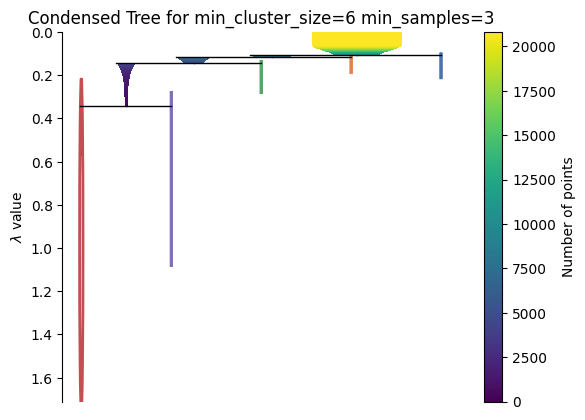

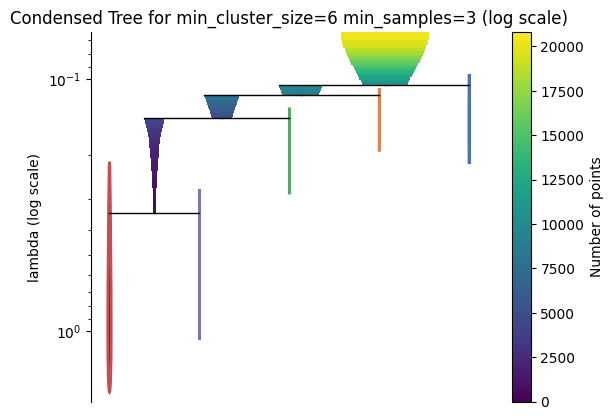

Silhouette Score (excluding outliers): 0.3383065433894893


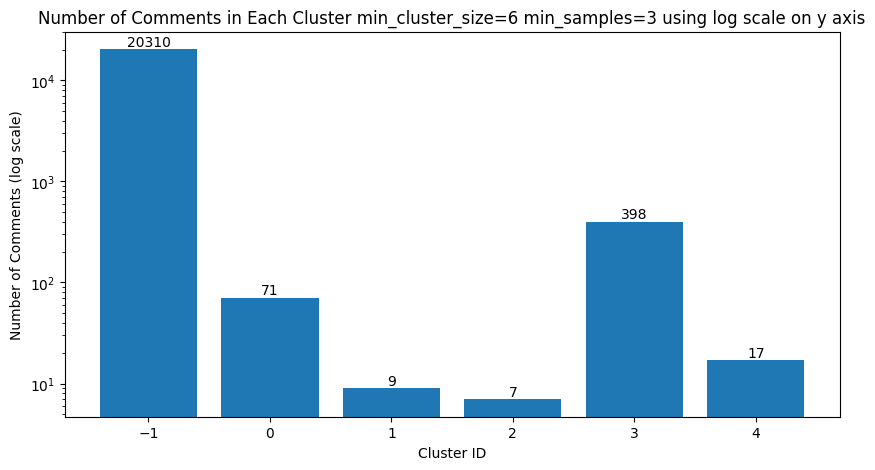

Cluster sizes:
 -1    20310
 3      398
 0       71
 4       17
 1        9
 2        7
Name: count, dtype: int64




Testing with hyperparameters:  {'min_cluster_size': 3, 'min_samples': 3}
Cluster persistence: [2.55314192e-03 1.23107419e-03 9.87575842e-03 1.00019981e-03
 5.25827317e-03 4.70795199e-03 9.69110770e-01 3.06923176e-04]


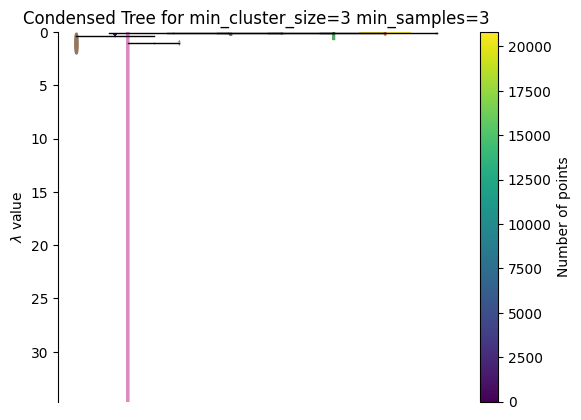

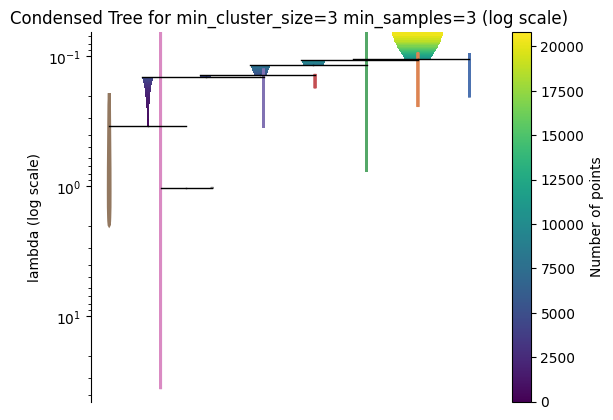

Silhouette Score (excluding outliers): 0.36333680812655367


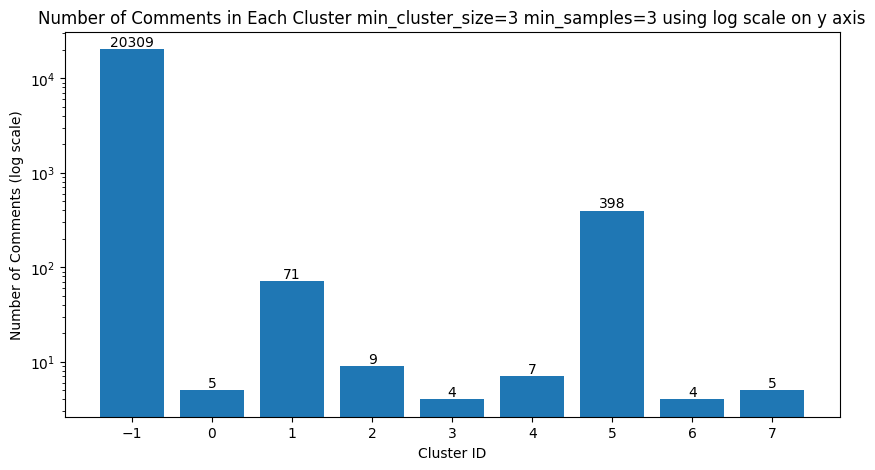

Cluster sizes:
 -1    20309
 5      398
 1       71
 2        9
 4        7
 7        5
 0        5
 6        4
 3        4
Name: count, dtype: int64






In [3]:
# hdbscan loop
labels_list = []
probabilities_list = []
hyperparameters_combinations = [
    {"min_cluster_size": 6, "min_samples": 6 },
    {"min_cluster_size": 6, "min_samples": 3 },
    {"min_cluster_size": 3, "min_samples": 3 }
]
cluster_persistence_list = []
for params in hyperparameters_combinations:
    print("Testing with hyperparameters: ", params)

    hdbscan = HDBSCAN(
        min_cluster_size=params["min_cluster_size"],
        min_samples=params["min_samples"],
        cluster_selection_method="leaf"
    )
    hdbscan_results = hdbscan.fit(X)
    
    #print the cluster persistence
    cluster_persistence_list.append(hdbscan_results.cluster_persistence_)
    print(f"Cluster persistence: {cluster_persistence_list[-1]}")

    #plot the condensed tree
    hdbscan_results.condensed_tree_.plot(select_clusters=True, selection_palette=sns.color_palette("deep", 10))
    plt.title(f"Condensed Tree for min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']}")
    plt.show()
    
    hdbscan_results.condensed_tree_.plot(select_clusters=True, selection_palette=sns.color_palette("deep", 10))
    plt.title(f"Condensed Tree for min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']} (log scale)")
    plt.yscale('log')
    plt.ylabel("lambda (log scale)")
    plt.show()

    labels = hdbscan_results.labels_
    labels_list.append(labels)
    #data["cluster"] = hdbscan_results.labels_
    np.save(f'hdbscan_labels_{params["min_cluster_size"]}_{params["min_samples"]}.npy', labels)
    # probabilities = hdbscan_results.probabilities_
    # probabilities_list.append(probabilities)
    # np.save(f'hdbscan_probabilities_{params["min_cluster_size"]}_{params["min_samples"]}.npy', probabilities)

    #Compute and print the silhouette score, ignoring outliers (label -1)
    try:
        mask = labels != -1
        score = silhouette_score(X[mask], labels[mask])
        print(f"Silhouette Score (excluding outliers): {score}")
    except Exception as e:
        print(f"Error calculating silhouette score: {e}")

    #Plot the number of comments for each cluster, with outliers as a separate bar
    plt.figure(figsize=(10, 5))
    cluster_sizes = pd.Series(labels).value_counts()
    plt.title(f"Number of Comments in Each Cluster min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']} using log scale on y axis")
    #plt.bar(["outliers"]+[str(i) for i in range(0, cluster_sizes.shape[0]-1)], cluster_sizes.values)
    bars = plt.bar(cluster_sizes.index, cluster_sizes.values)
    plt.xlabel("Cluster ID")
    plt.ylabel("Number of Comments (log scale)")
    plt.xticks(cluster_sizes.index)
    #log scale on y axis
    plt.yscale('log')
    plt.bar_label(bars, labels=cluster_sizes.values)
    plt.show()
    print("Cluster sizes:\n", cluster_sizes)

    # plt.figure(figsize=(8, 5))
    # for i in range(0, cluster_sizes.shape[0]):
    #         sns.kdeplot(
    #         probabilities[labels==i],
    #         label=f"Cluster {i}"
    #     )
    # plt.legend()
    # plt.title("Probability Density per Cluster")
    # plt.show()

    print("\n\n\n")

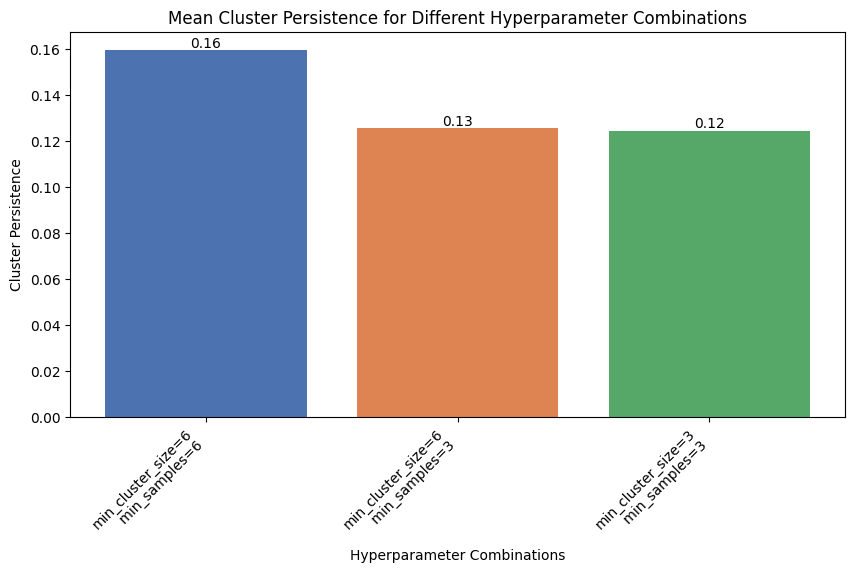

In [4]:
#plot the cluster persistence for each hyperparameter combination
plt.figure(figsize=(10, 5))
#use mean persistence, and 0 when no clusters are found
persistence_values = [
    float(np.mean(cp)) if np.asarray(cp).size > 0 else 0.0
    for cp in cluster_persistence_list
]
bars = plt.bar(
    range(len(hyperparameters_combinations)),
    persistence_values,
    color=sns.color_palette("deep", len(hyperparameters_combinations))
)
plt.bar_label(bars, fmt="%.2f")
plt.xticks(range(len(hyperparameters_combinations)), [f"min_cluster_size={params['min_cluster_size']}\n min_samples={params['min_samples']}" for params in hyperparameters_combinations], rotation=45, ha='right')    
plt.xlabel("Hyperparameter Combinations")
plt.ylabel("Cluster Persistence")
plt.title("Mean Cluster Persistence for Different Hyperparameter Combinations")
plt.show()

In [5]:
# index = int(input("Index of the hyperparameters combination to visualize (0, 1, or 2): "))
# data['cluster']=labels_list[index]
# #probabilities=probabilities_list[index]
# params = hyperparameters_combinations[index]

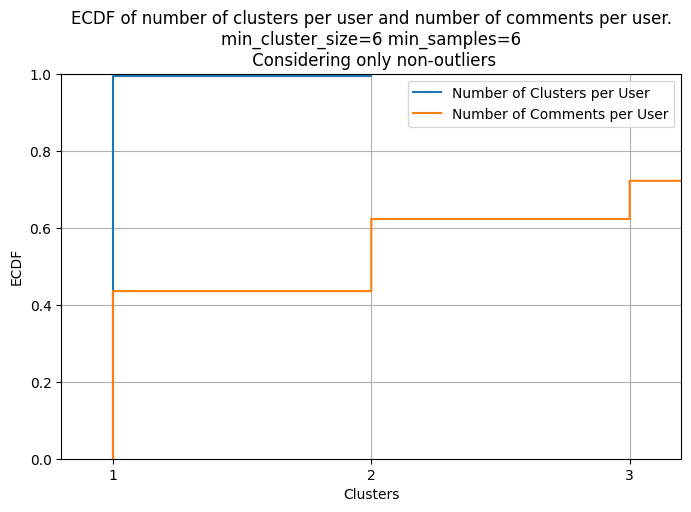

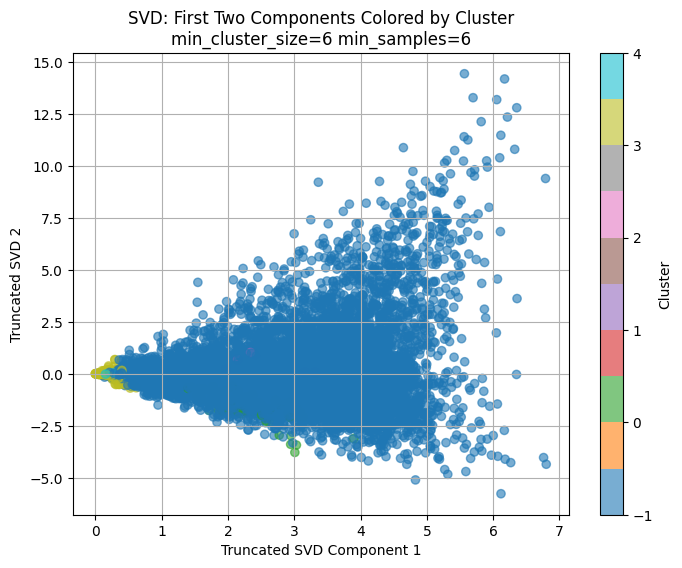

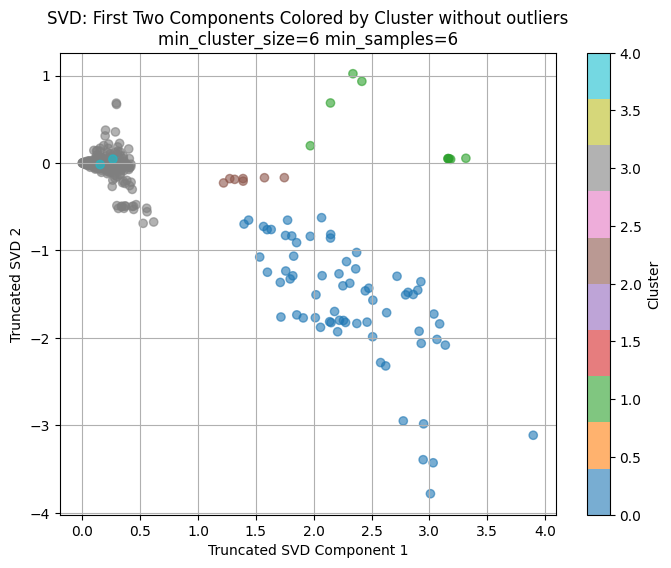

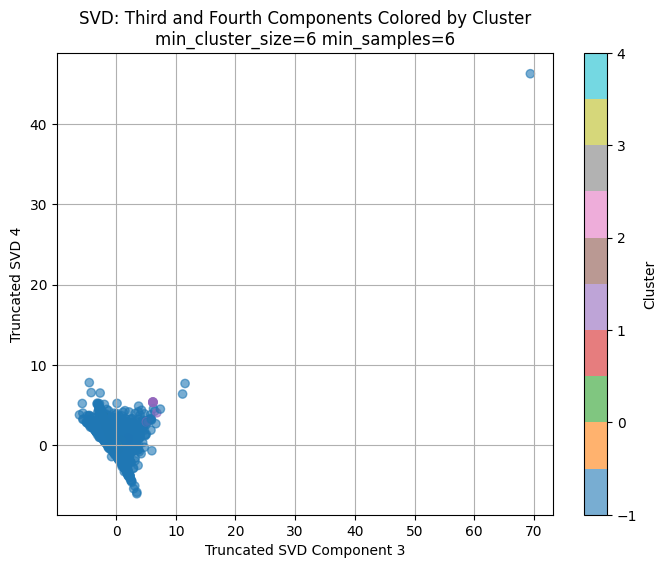

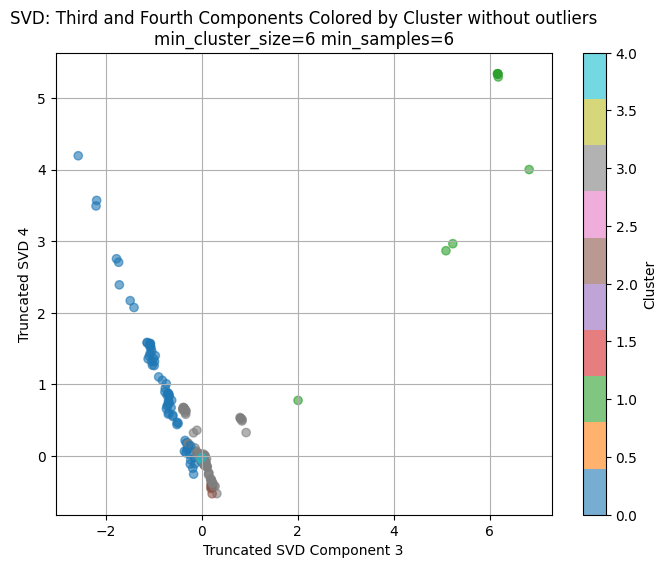

cluster 3 has 382 comments


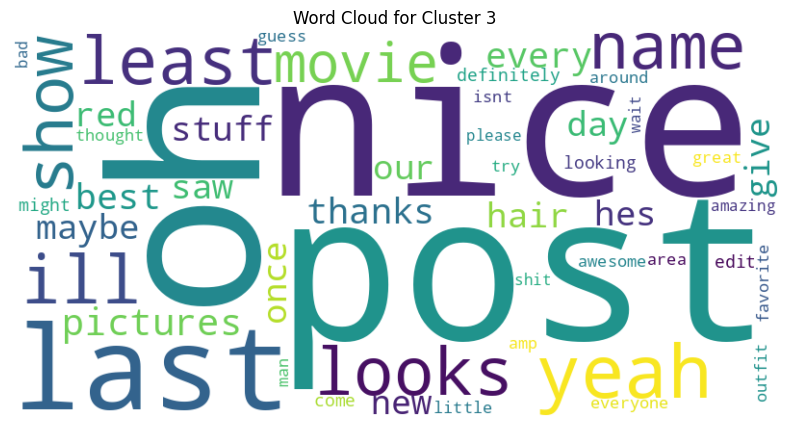

cluster 0 has 67 comments


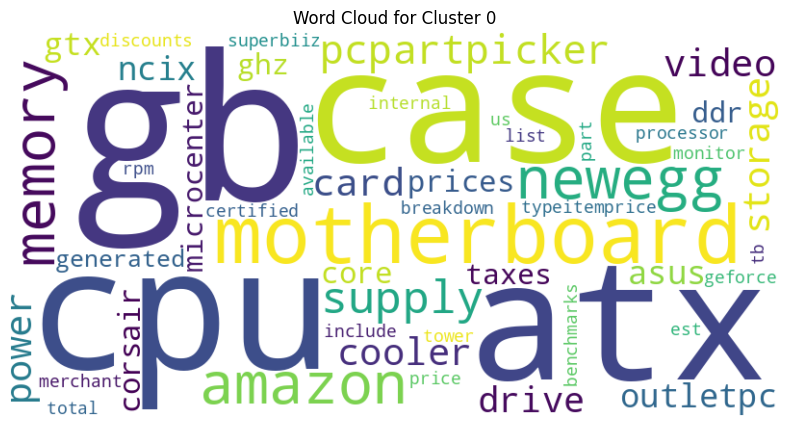

cluster 4 has 17 comments


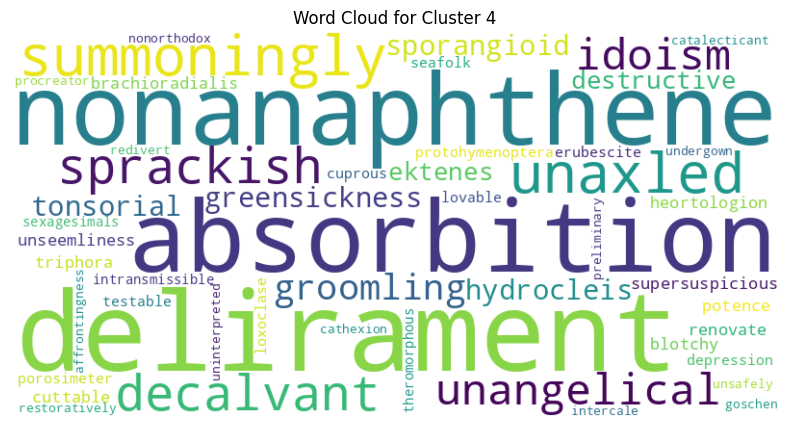

cluster 1 has 9 comments


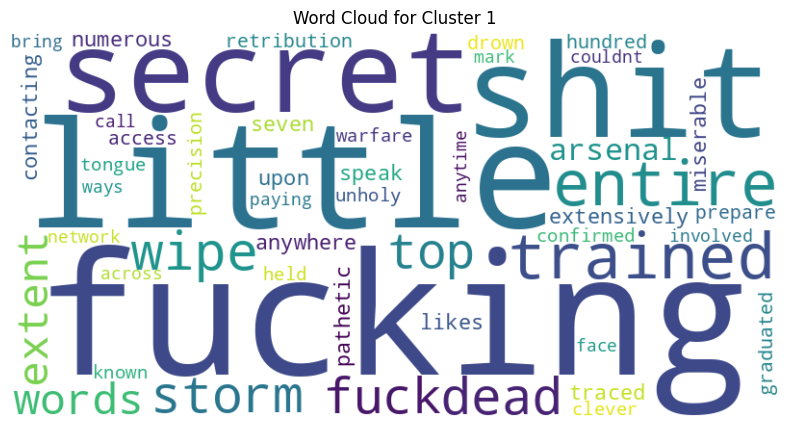

cluster 2 has 7 comments


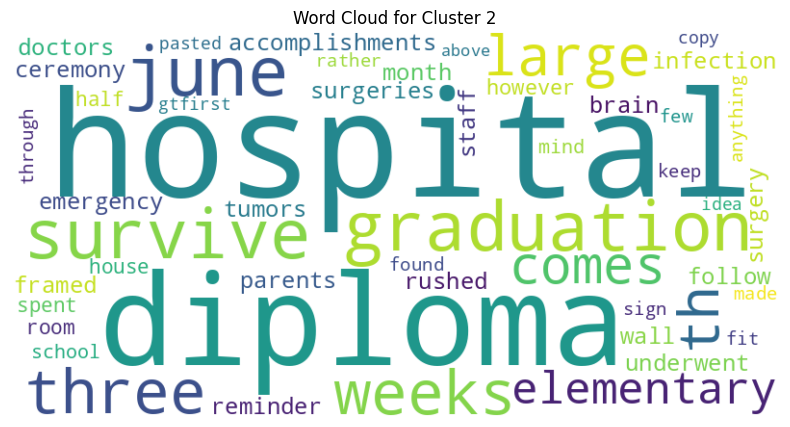

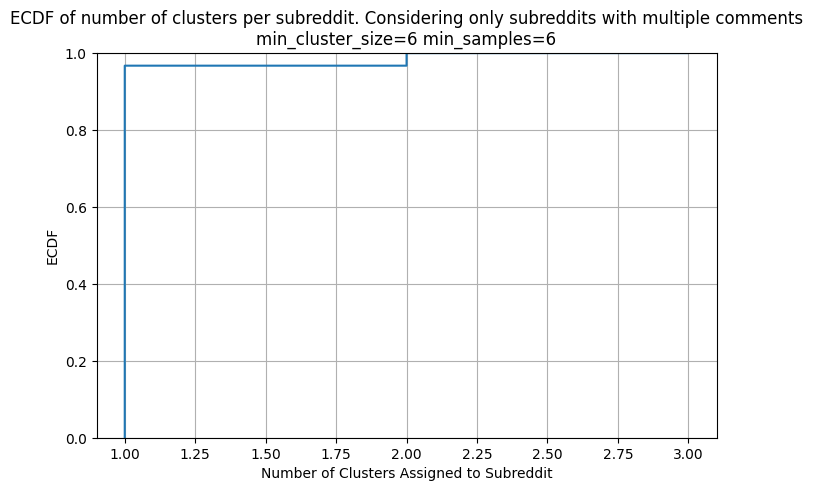

Cluster 3 has 382 comments and 367 subreddits


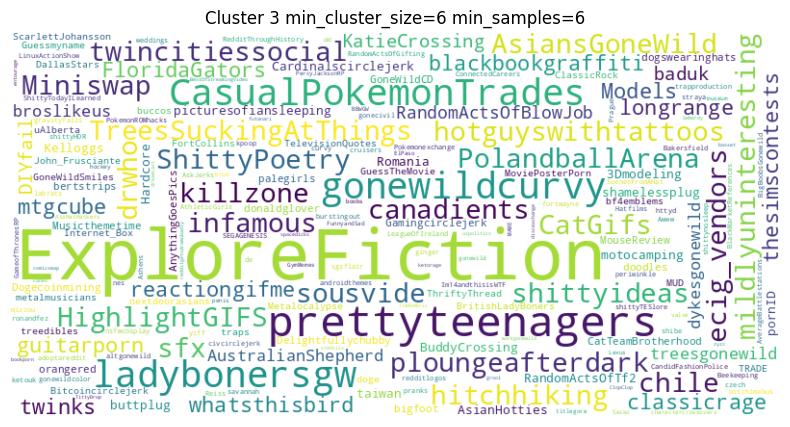

Cluster 0 has 67 comments and 5 subreddits


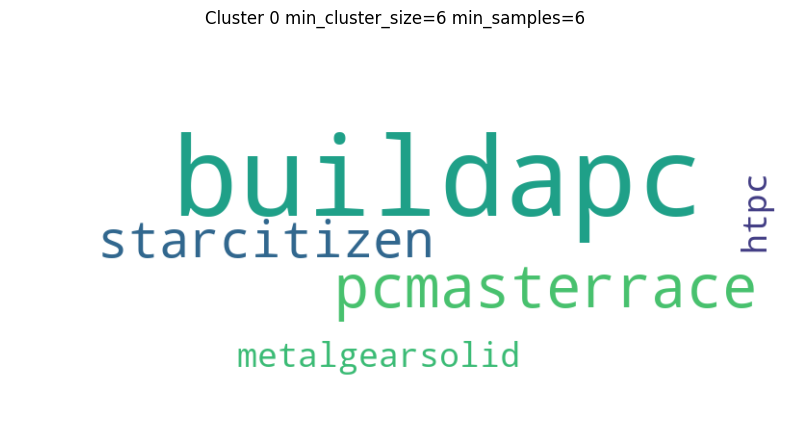

Cluster 4 has 17 comments and 10 subreddits


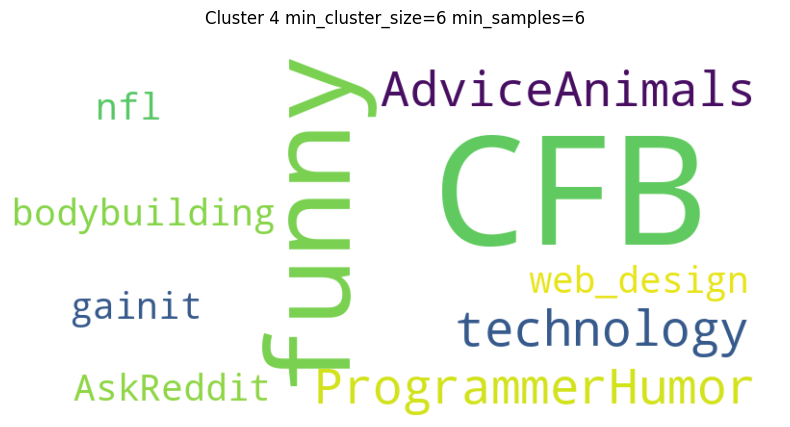

Cluster 1 has 9 comments and 9 subreddits


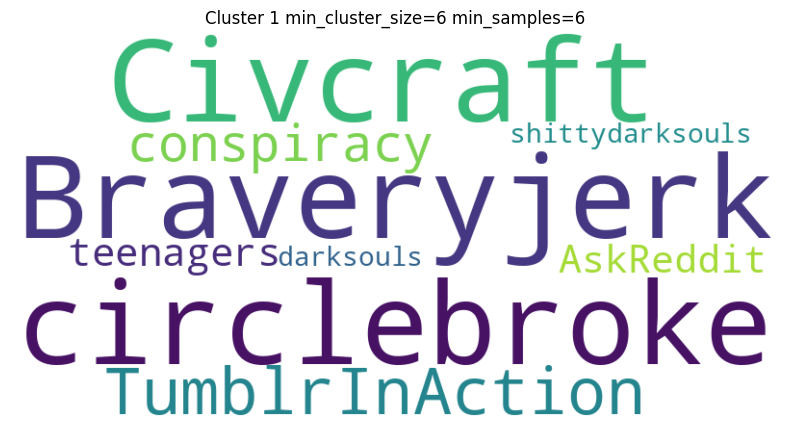

Cluster 2 has 7 comments and 1 subreddits


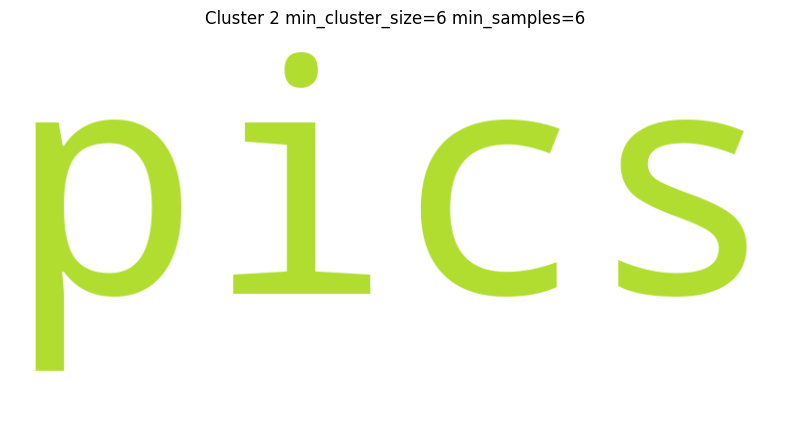

ARI: 0.0015666056289172533
NMI: 0.03563576228476075
AMI: 0.023050019395165714
Considerind only non-outliers:
ARI: 0.016499611319159998
NMI: 0.22669890040242852
AMI: 0.046348894827104144


/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)


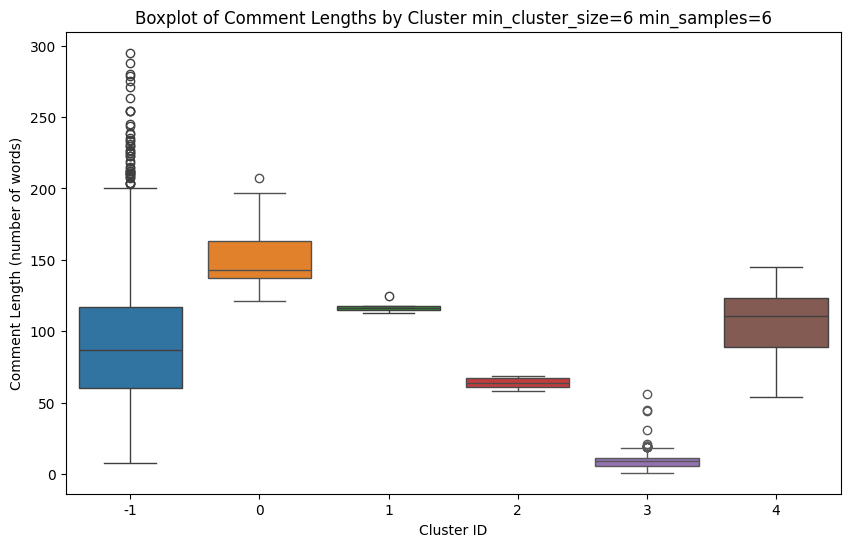

Cluster -1:
  Min length: 8 words
  25th percentile: 60.0 words
  Average length: 88.26 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 121 words
  25th percentile: 137.0 words
  Average length: 150.96 words
  75th percentile: 163.5 words
  Max length: 207 words
Cluster 1:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 2:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 3:
  Min length: 1 words
  25th percentile: 6.0 words
  Average length: 9.29 words
  75th percentile: 11.0 words
  Max length: 56 words
Cluster 4:
  Min length: 54 words
  25th percentile: 89.0 words
  Average length: 104.82 words
  75th percentile: 123.0 words
  Max length: 145 words


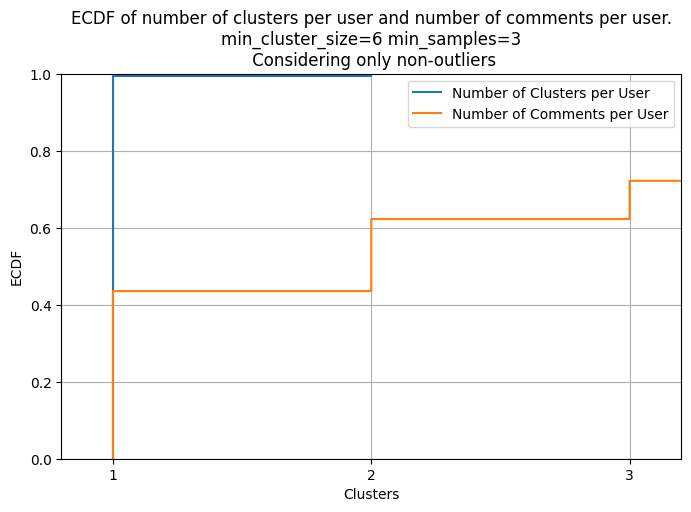

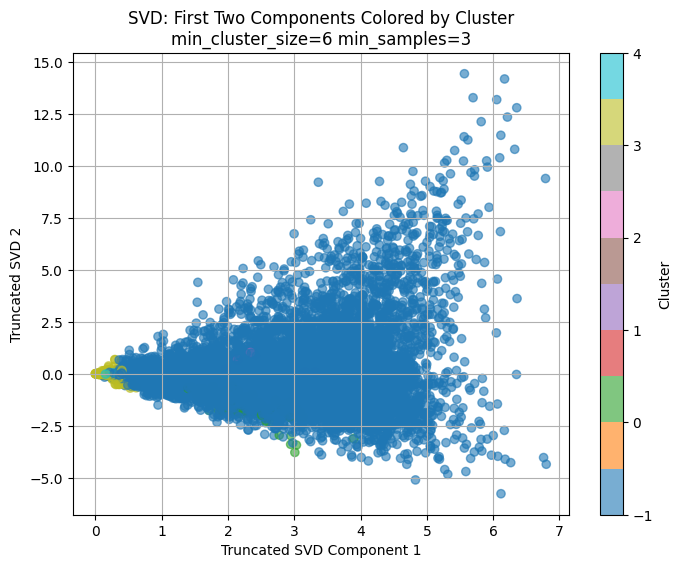

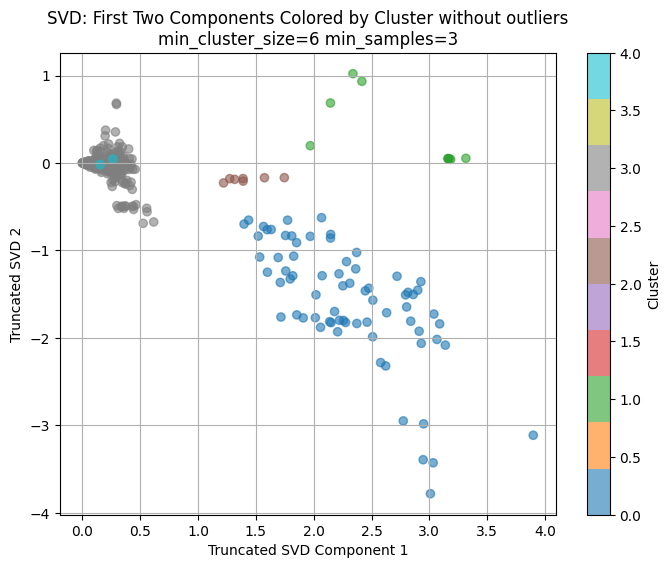

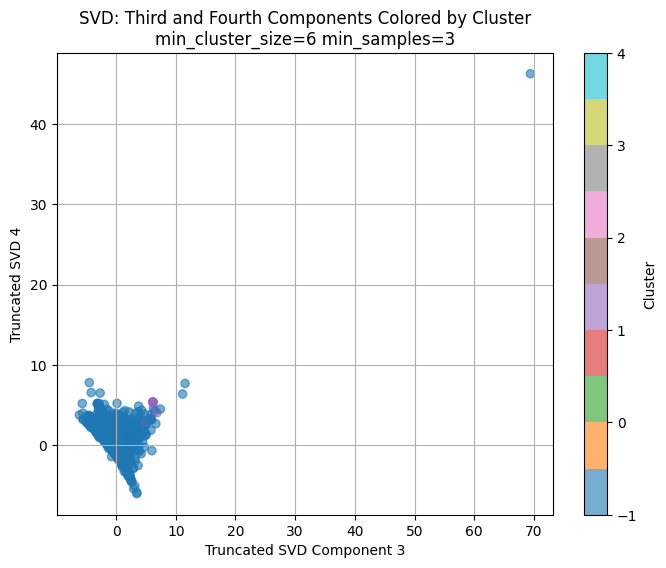

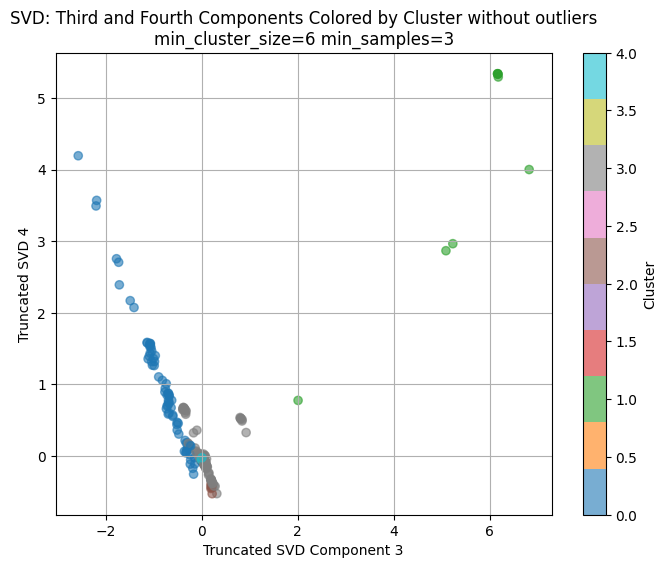

cluster 3 has 398 comments


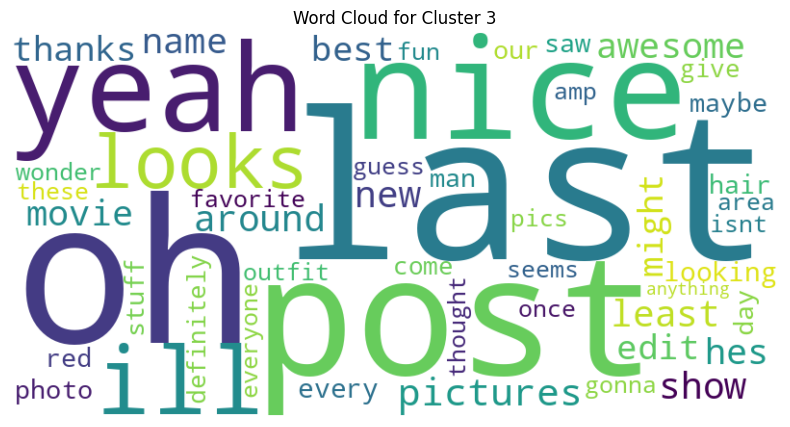

cluster 0 has 71 comments


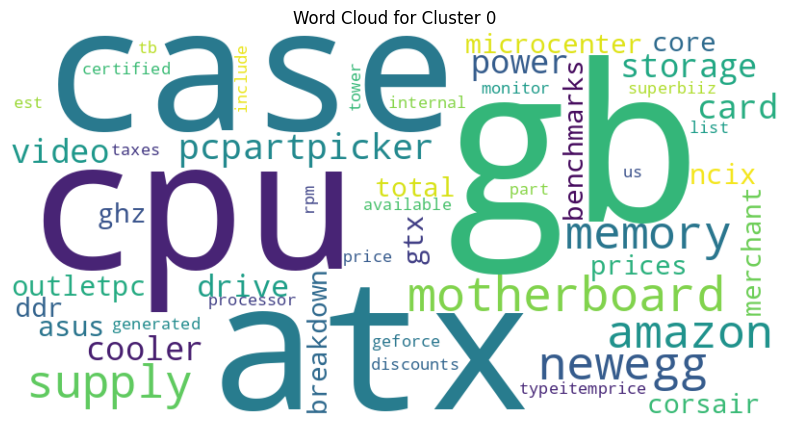

cluster 4 has 17 comments


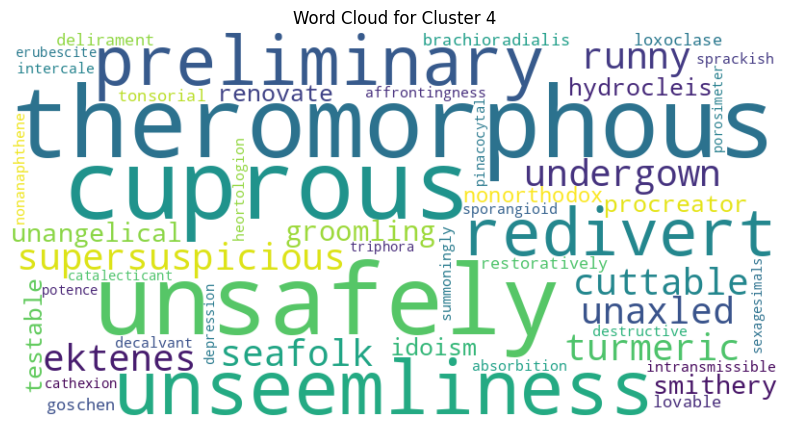

cluster 1 has 9 comments


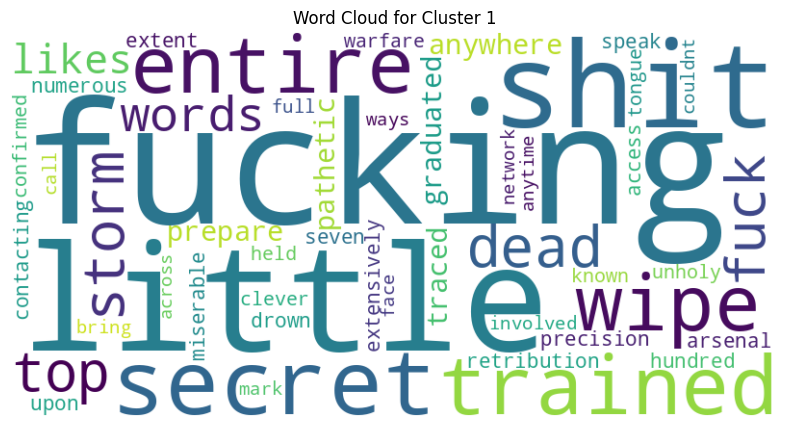

cluster 2 has 7 comments


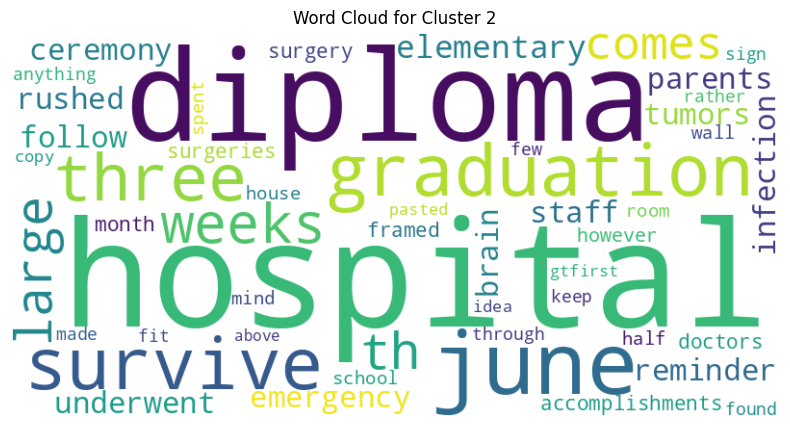

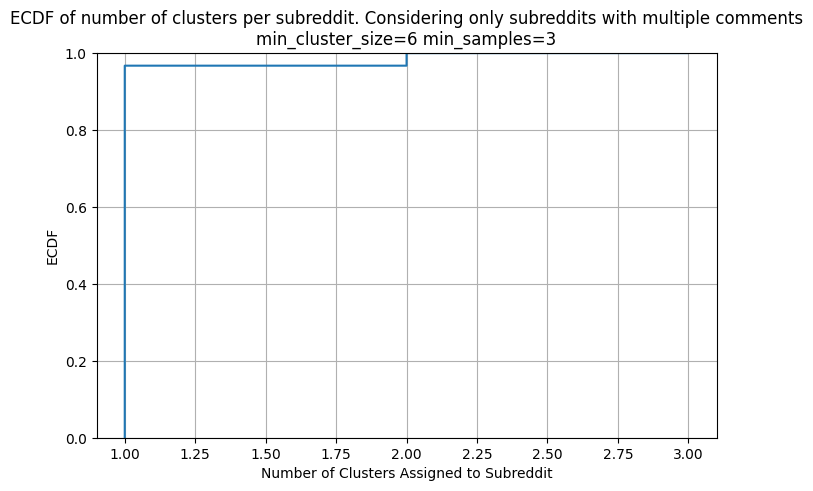

Cluster 3 has 398 comments and 382 subreddits


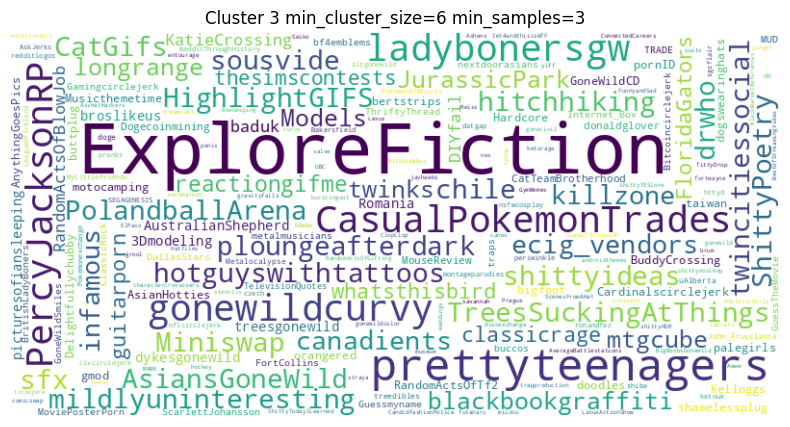

Cluster 0 has 71 comments and 5 subreddits


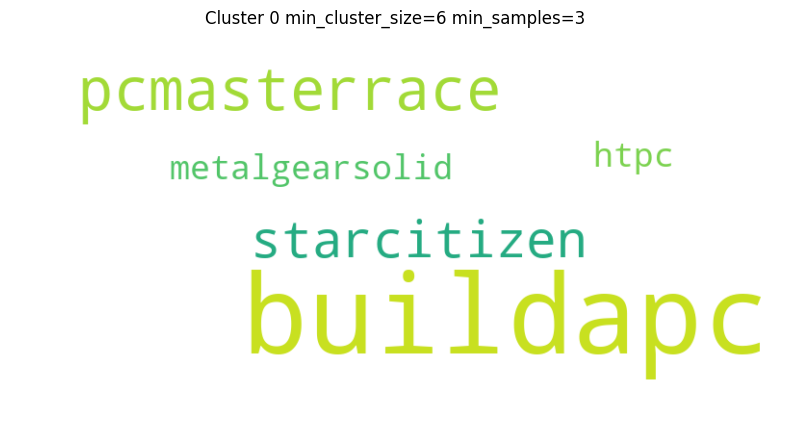

Cluster 4 has 17 comments and 10 subreddits


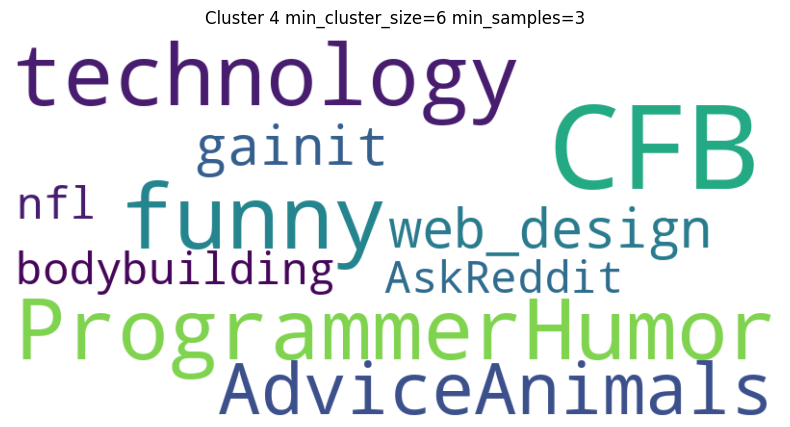

Cluster 1 has 9 comments and 9 subreddits


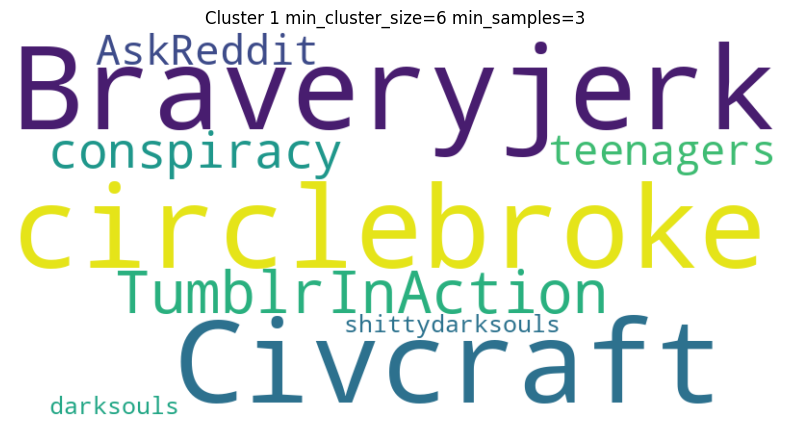

Cluster 2 has 7 comments and 1 subreddits


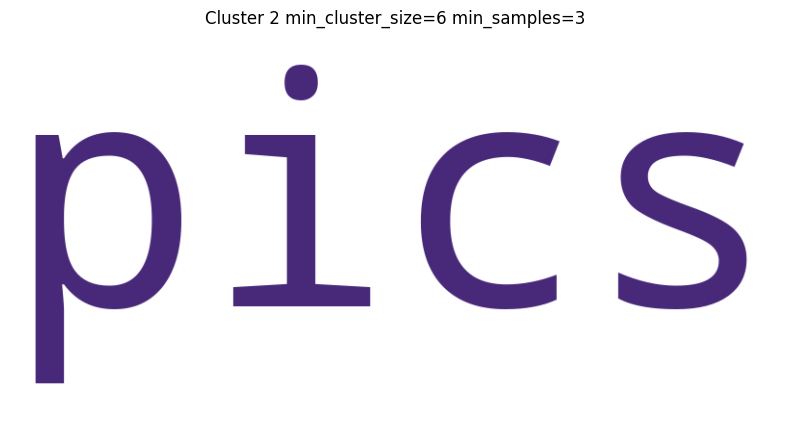

ARI: 0.0016394580064414388
NMI: 0.03691471204248438
AMI: 0.024031927713981206
Considerind only non-outliers:
ARI: 0.017211803606410007
NMI: 0.22442072643179578
AMI: 0.046524418076229715


/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)


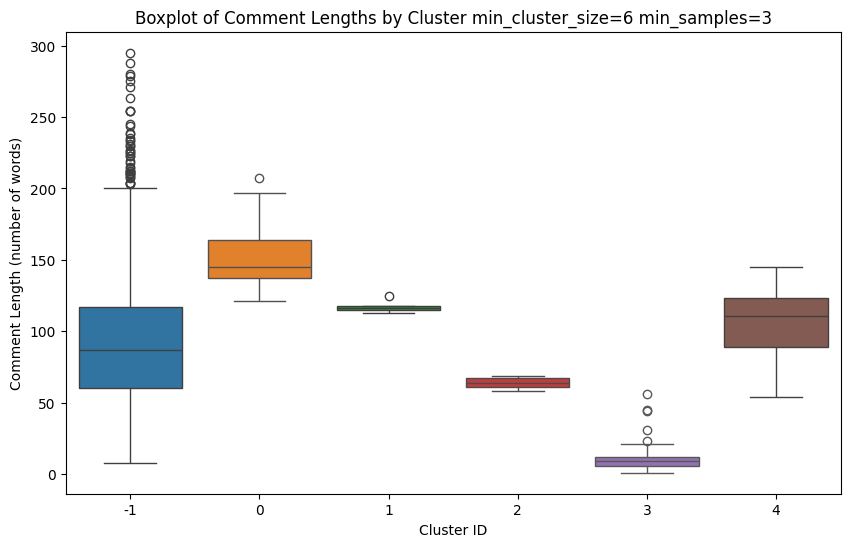

Cluster -1:
  Min length: 8 words
  25th percentile: 60.0 words
  Average length: 88.30 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 121 words
  25th percentile: 137.5 words
  Average length: 151.31 words
  75th percentile: 164.0 words
  Max length: 207 words
Cluster 1:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 2:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 3:
  Min length: 1 words
  25th percentile: 6.0 words
  Average length: 9.49 words
  75th percentile: 12.0 words
  Max length: 56 words
Cluster 4:
  Min length: 54 words
  25th percentile: 89.0 words
  Average length: 104.82 words
  75th percentile: 123.0 words
  Max length: 145 words


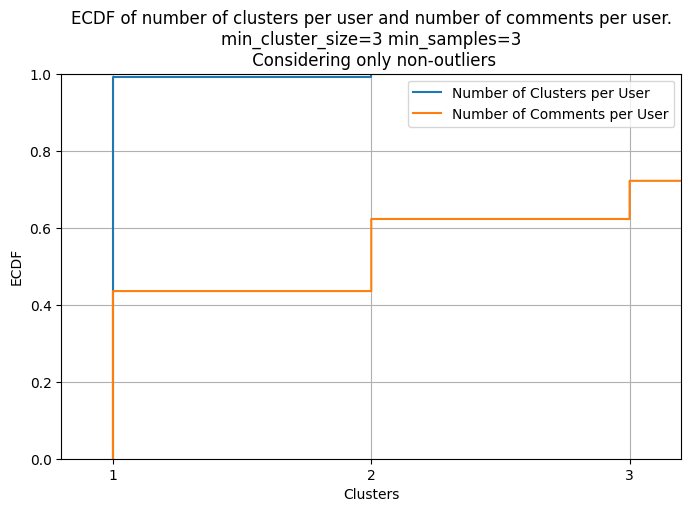

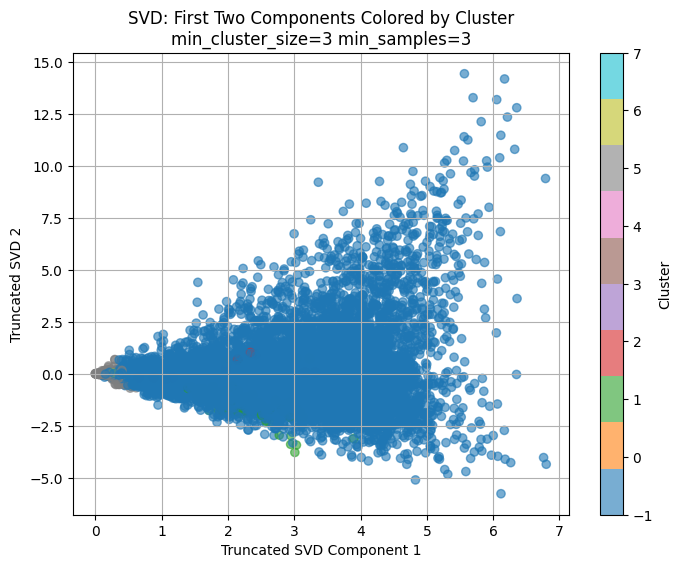

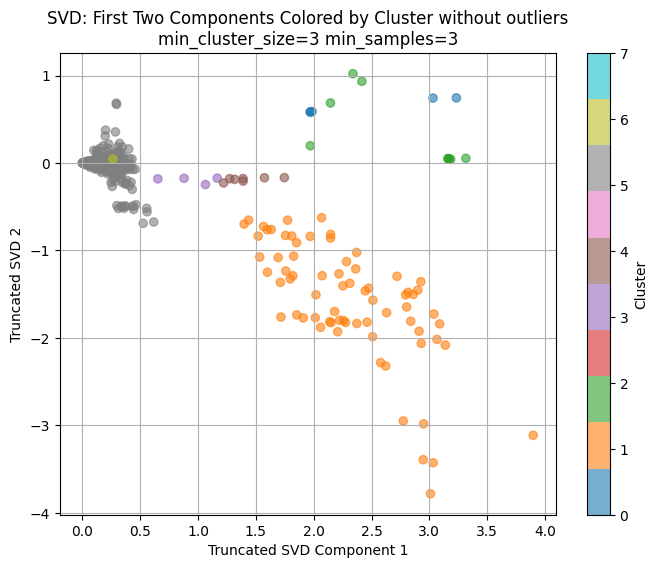

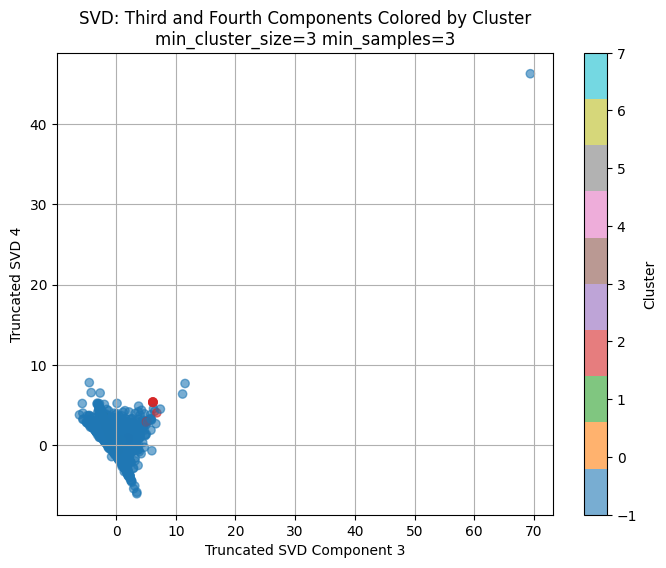

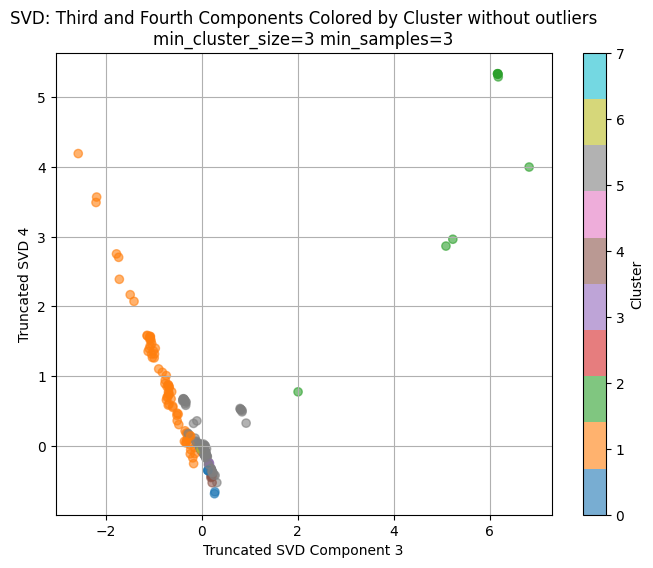

cluster 5 has 398 comments


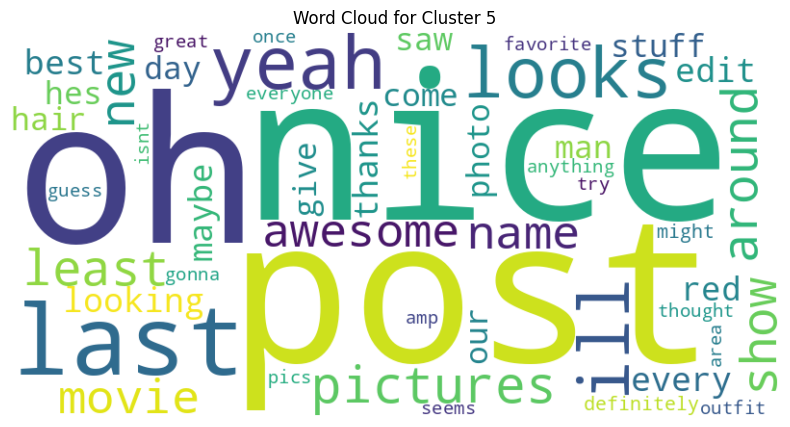

cluster 1 has 71 comments


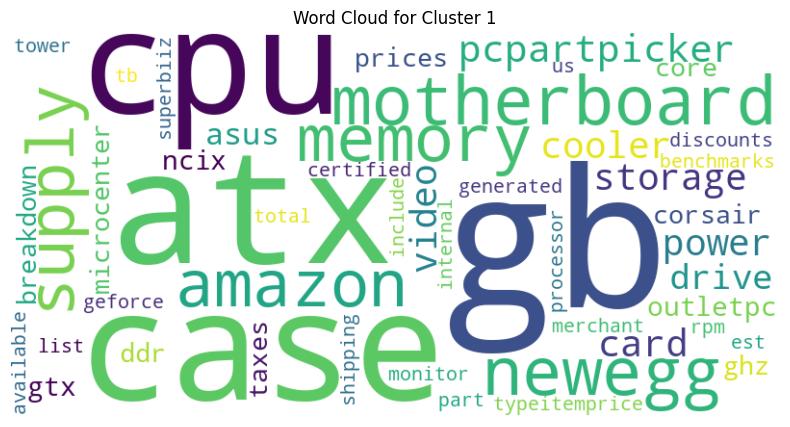

cluster 2 has 9 comments


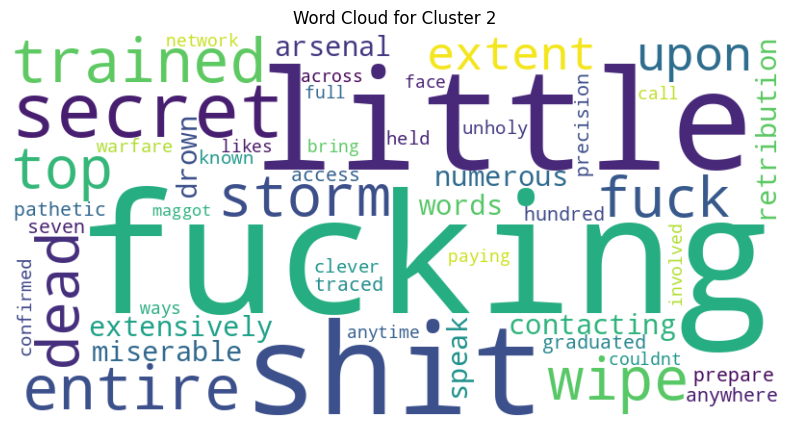

cluster 4 has 7 comments


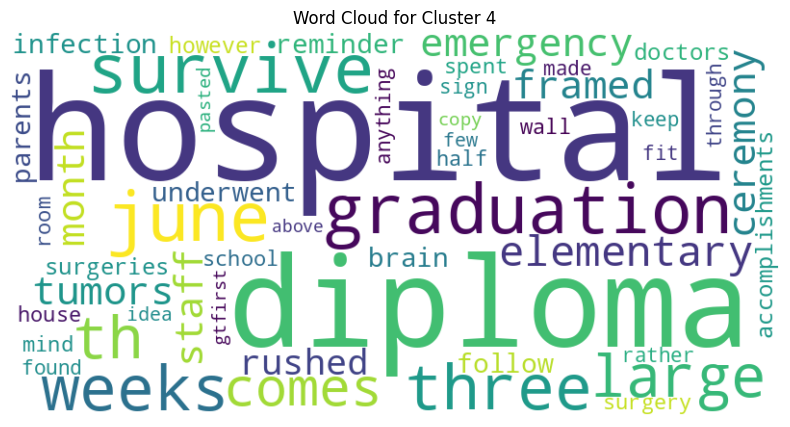

cluster 7 has 5 comments


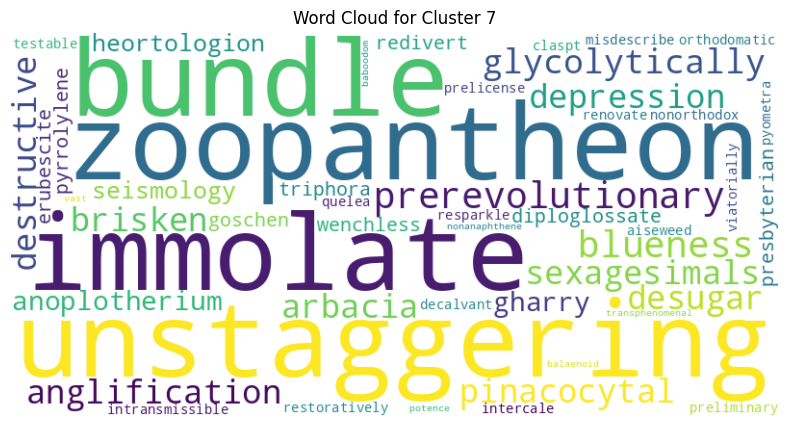

cluster 0 has 5 comments


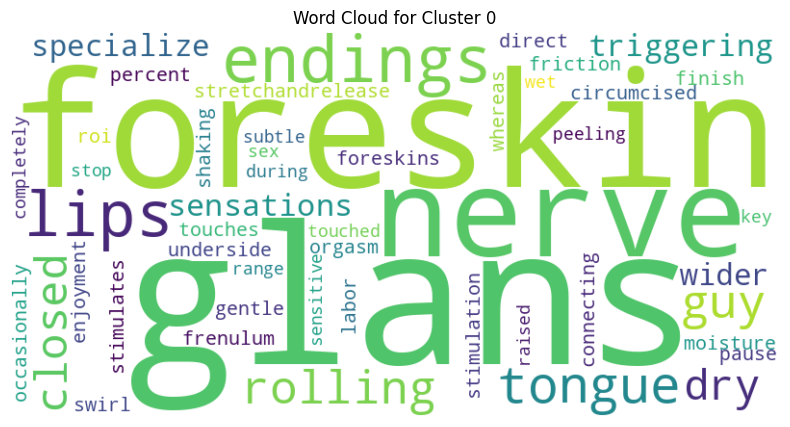

cluster 6 has 4 comments


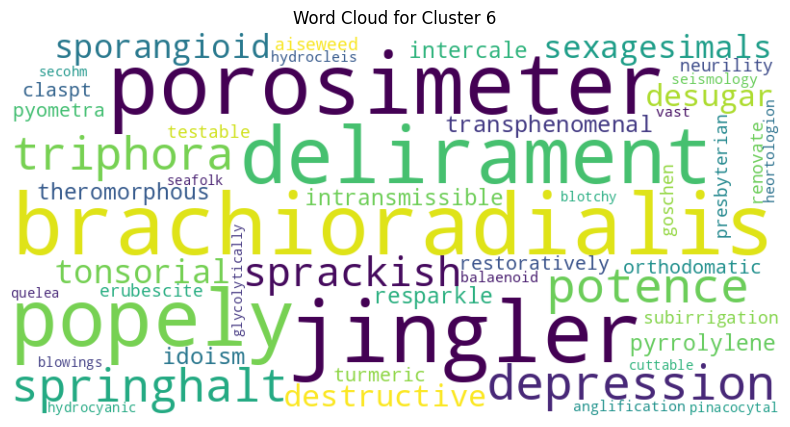

cluster 3 has 4 comments


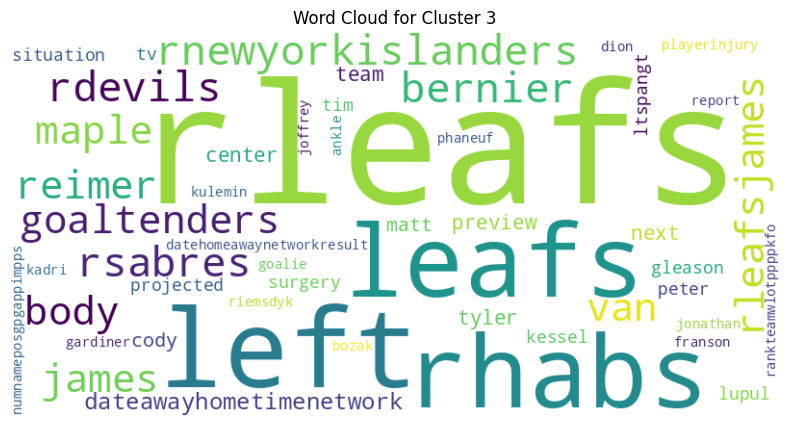

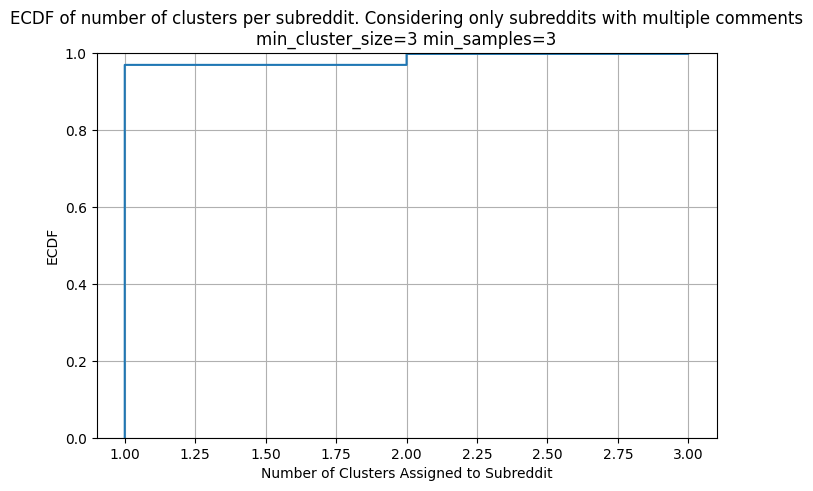

Cluster 5 has 398 comments and 382 subreddits


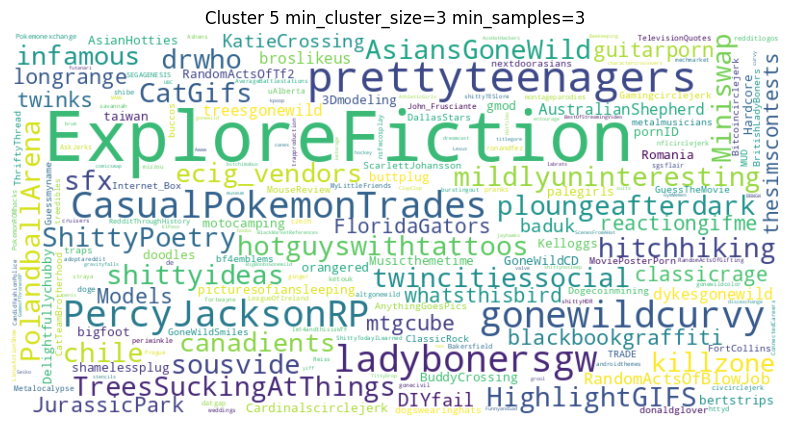

Cluster 1 has 71 comments and 5 subreddits


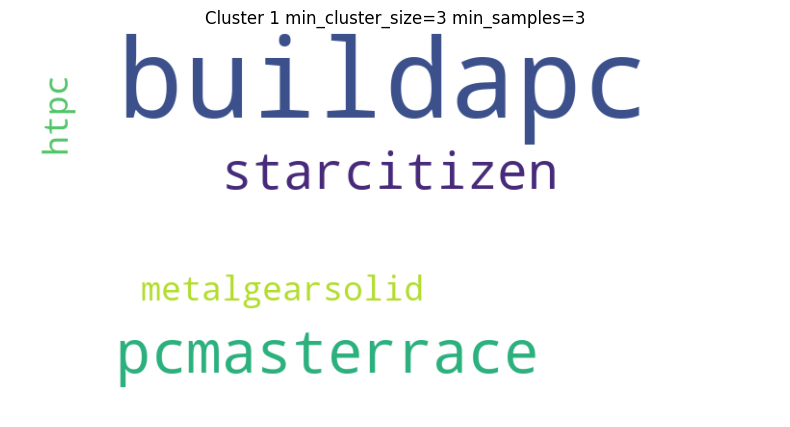

Cluster 2 has 9 comments and 9 subreddits


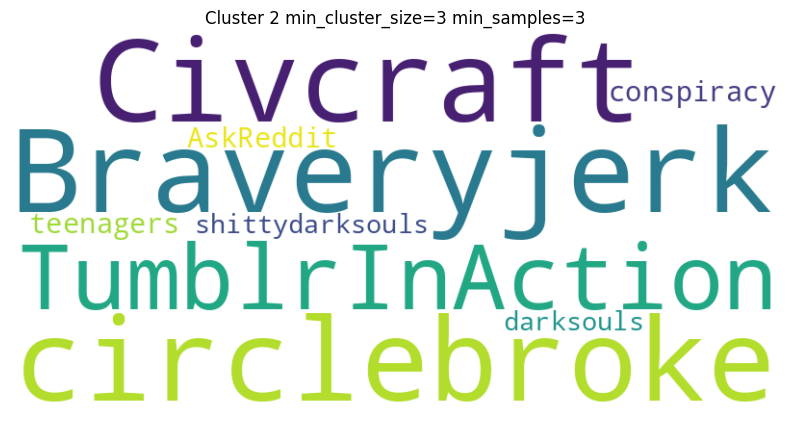

Cluster 4 has 7 comments and 1 subreddits


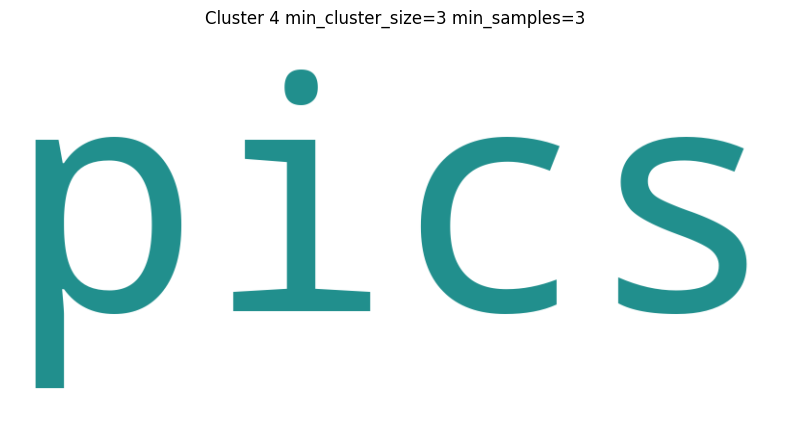

Cluster 7 has 5 comments and 4 subreddits


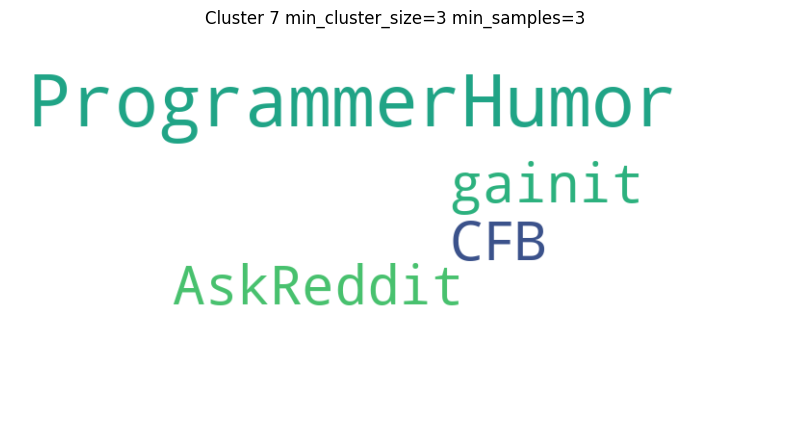

Cluster 0 has 5 comments and 1 subreddits


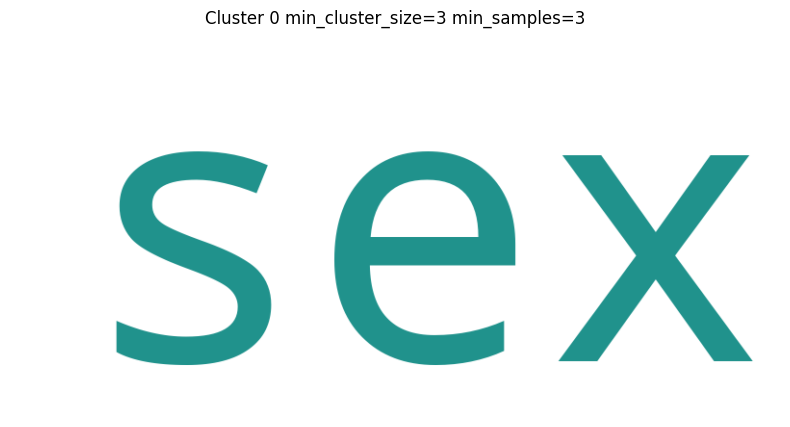

Cluster 6 has 4 comments and 4 subreddits


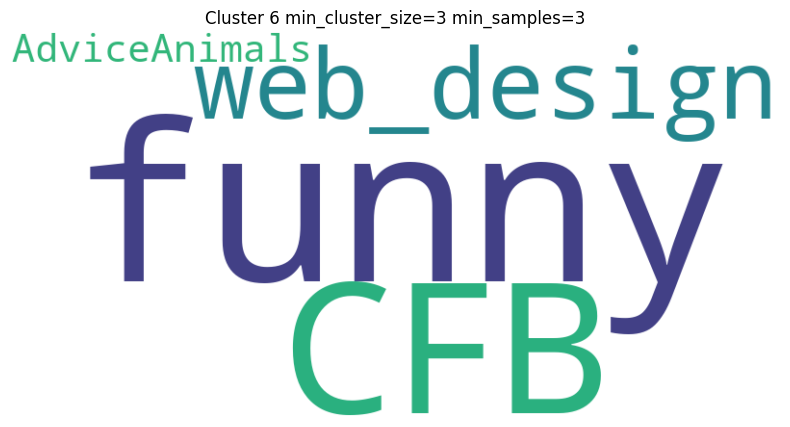

Cluster 3 has 4 comments and 1 subreddits


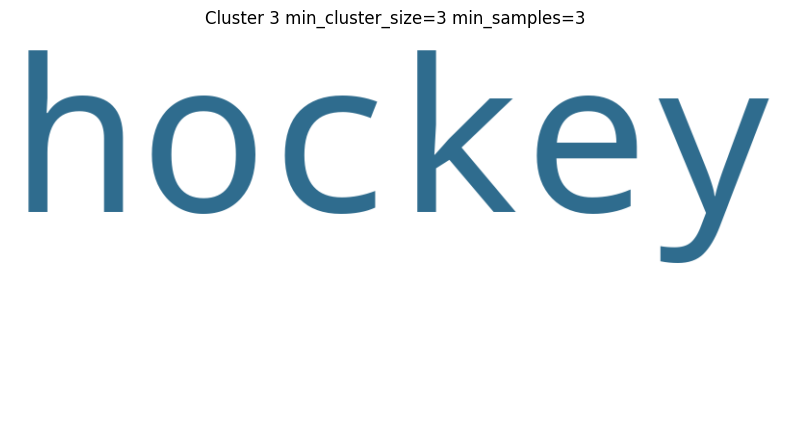

ARI: 0.001647387911905472
NMI: 0.037360684270532935
AMI: 0.024101292189424545
Considerind only non-outliers:
ARI: 0.01738088569831045
NMI: 0.23776728691316526
AMI: 0.047067963325546164


/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)
/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/sklearn/metrics/cluster/_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)


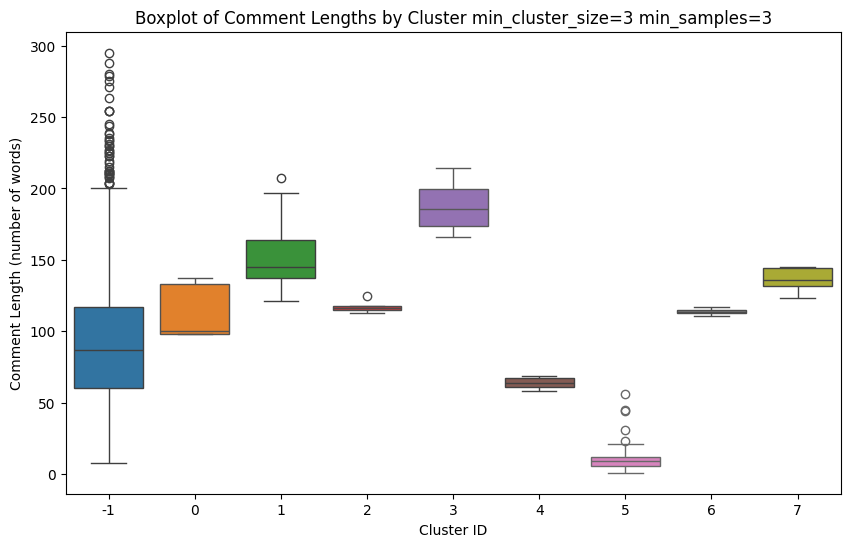

Cluster -1:
  Min length: 8 words
  25th percentile: 60.0 words
  Average length: 88.27 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 98 words
  25th percentile: 98.0 words
  Average length: 113.20 words
  75th percentile: 133.0 words
  Max length: 137 words
Cluster 1:
  Min length: 121 words
  25th percentile: 137.5 words
  Average length: 151.31 words
  75th percentile: 164.0 words
  Max length: 207 words
Cluster 2:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 3:
  Min length: 166 words
  25th percentile: 173.5 words
  Average length: 187.75 words
  75th percentile: 199.75 words
  Max length: 214 words
Cluster 4:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 5:
  Min length: 1 words
  25th percentile: 6.0 words
  Average length: 9.49 words
  75th

In [6]:
for index in range(len(hyperparameters_combinations)):
    params = hyperparameters_combinations[index] 
    data['cluster'] = labels_list[index]
    cluster_sizes = data['cluster'].value_counts()

    # ECDF of number of clusters per user and number of comments per user, considering only non-outliers
    non_outlier_mask = data['cluster'] != -1
    user_clusters = data[non_outlier_mask].groupby('author')['cluster'].nunique().reset_index()  # grouping by author
    # user_clusters is now a series with author and number of clusters
    user_clusters.columns = ['author', 'num_clusters']  # turn it into a DF
    user_comments = data.groupby('author')['body'].nunique().reset_index()
    user_comments.columns = ['author', 'num_comments']
    # # Filter user_clusters to only those authors who have multiple comments
    # authors_with_multiple_comments = data_no_outliers.groupby('author')['body'].nunique()
    # authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
    # user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=user_clusters, x='num_clusters')
    sns.ecdfplot(data=user_comments, x='num_comments')
    plt.xlabel('Clusters')
    plt.ylabel('ECDF')
    plt.title(f'ECDF of number of clusters per user and number of comments per user.\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}\n Considering only non-outliers')
    plt.grid(True)
    x_max = user_clusters['num_clusters'].max() + 1
    plt.xlim(0.8, x_max + 0.2)
    plt.xticks(range(1, x_max + 1))
    plt.legend(['Number of Clusters per User', 'Number of Comments per User'])
    plt.show()

    # Plot the first two components of the SVD, colored by cluster, with and without outliers
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 1')
    plt.ylabel('Truncated SVD 2')
    plt.title(f'SVD: First Two Components Colored by Cluster\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[non_outlier_mask][:, 0], X[non_outlier_mask][:, 1], c=data[non_outlier_mask]['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 1')
    plt.ylabel('Truncated SVD 2')
    plt.title(f'SVD: First Two Components Colored by Cluster without outliers\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()
    # Plot the third and fourth components of the SVD, colored by cluster, with and without outliers
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 2], X[:, 3], c=data['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 3')
    plt.ylabel('Truncated SVD 4')
    plt.title(f'SVD: Third and Fourth Components Colored by Cluster\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[non_outlier_mask][:, 2], X[non_outlier_mask][:, 3], c=data[non_outlier_mask]['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 3')
    plt.ylabel('Truncated SVD 4')
    plt.title(f'SVD: Third and Fourth Components Colored by Cluster without outliers\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()

    # WORD CLOUDS
    # Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
    cluster_documents = data[non_outlier_mask][['body', 'cluster']].groupby('cluster').agg(' '.join)
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
    terms = tfidf_vectorizer.get_feature_names_out()
    cluster_to_row = {cluster_label: row_index for row_index, cluster_label in enumerate(cluster_documents.index)}
    if len(set(data[non_outlier_mask]['cluster'])) > 10:
        # List the first 8 largest clusters
        clusters_to_plot = data[non_outlier_mask]['cluster'].value_counts().nlargest(8).index
        # add two clusters from the smallest
        clusters_to_plot = clusters_to_plot.append(data[non_outlier_mask]['cluster'].value_counts().nsmallest(2).index)
    else:
        clusters_to_plot = data[non_outlier_mask]['cluster'].value_counts().index
    # For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
    for cluster_num in clusters_to_plot:
        row_index = cluster_to_row[cluster_num]
        tfidf_scores = tfidf_matrix[row_index].toarray().flatten()
        top_indices = np.argsort(tfidf_scores)[-50:]
        top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)
        print(f"cluster {cluster_num} has {cluster_sizes[cluster_num]} comments")
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'Word Cloud for Cluster {cluster_num}')
        plt.show()
        # if cluster_sizes[cluster_num]<10:
        #     for comment in data[labels != -1][data_no_outliers['cluster'] == cluster_num]['body'].values:
        #         print(comment)

    # ECDF of number of clusters per subreddit, considering only subreddits with multiple comments
    subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()  # grouping by subreddit
    # subreddit_clusters is now a series with subreddit and number of clusters
    subreddit_cluster.columns = ['subreddit', 'num_clusters']  # turn it into a DF
    # Filter subreddit_cluster to only those subreddits that have multiple comments
    subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
    subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
    subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
    plt.xlabel('Number of Clusters Assigned to Subreddit')
    plt.ylabel('ECDF')
    plt.title(f'ECDF of number of clusters per subreddit. Considering only subreddits with multiple comments\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.grid(True)
    plt.show()

    for cluster_num in clusters_to_plot:
        cluster_sizes = data[non_outlier_mask]['cluster'].value_counts()
        subreddits_names = ' '.join(data[non_outlier_mask][data[non_outlier_mask]['cluster'] == cluster_num]['subreddit'].values)
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subreddits_names)

        print(f"Cluster {cluster_num} has {cluster_sizes[cluster_num]} comments and {data[non_outlier_mask][data[non_outlier_mask]['cluster'] == cluster_num]['subreddit'].nunique()} subreddits")
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f"Cluster {cluster_num} min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']}")
        plt.show()

    # compute ARI, NMI, AMI between the clusters and the subreddits with and without outliers
    ari = adjusted_rand_score(data['subreddit'], data['cluster'])
    nmi = normalized_mutual_info_score(data['subreddit'], data['cluster'])
    ami = adjusted_mutual_info_score(data['subreddit'], data['cluster'])
    print('ARI:', ari)
    print('NMI:', nmi)
    print('AMI:', ami)
    ari = adjusted_rand_score(data[non_outlier_mask]['subreddit'], data[non_outlier_mask]['cluster'])
    nmi = normalized_mutual_info_score(data[non_outlier_mask]['subreddit'], data[non_outlier_mask]['cluster'])
    ami = adjusted_mutual_info_score(data[non_outlier_mask]['subreddit'], data[non_outlier_mask]['cluster'])
    print('Considerind only non-outliers:')
    print('ARI:', ari)
    print('NMI:', nmi)
    print('AMI:', ami)

    # plot for each cluster the length of comments (boxplot)
    plt.figure(figsize=(10, 6))
    for i in range(-1, cluster_sizes.shape[0]):
        cluster_data = data[data['cluster'] == i]
        sns.boxplot(x=cluster_data['cluster'], y=cluster_data['body'].apply(lambda x: len(x.split())))
    plt.xlabel('Cluster ID')
    plt.ylabel('Comment Length (number of words)')
    plt.title(f'Boxplot of Comment Lengths by Cluster min_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.show()

    # print for each cluster average length of comments, max, min 25th percentile, 75th percentile
    for i in range(-1, cluster_sizes.shape[0]):
        cluster_data = data[data['cluster'] == i]
        comment_lengths = cluster_data['body'].apply(lambda x: len(x.split()))
        print(f'Cluster {i}:')
        print(f'  Min length: {comment_lengths.min()} words')
        print(f'  25th percentile: {comment_lengths.quantile(0.25)} words')
        print(f'  Average length: {comment_lengths.mean():.2f} words')
        print(f'  75th percentile: {comment_lengths.quantile(0.75)} words')
        print(f'  Max length: {comment_lengths.max()} words')
